# 08 — Shipment & Delivery Analysis

## Sales Order, Backlog & Inventory Analytics

### Objective

This notebook analyzes shipment execution and customer delivery performance across the fulfillment network.

The analysis focuses on:

- Overall shipment KPIs
- Valid vs invalid shipment chronology
- On-time delivery performance
- OTIF performance
- Delivery delay analysis
- Delay severity
- Monthly and quarterly delivery trends
- Delivery performance by warehouse
- Delivery performance by customer region
- Delivery performance by priority
- Delivery performance by sales channel
- High-delay shipments
- Shipment and delivery risk areas

### Data Quality Rule

Shipment records where `actual_delivery_date < shipment_date` are classified as invalid chronology records.

These records are retained for transparency but excluded from clean delivery-performance KPIs using:

- `chronology_valid_flag`
- `delivery_delay_days_clean`
- `on_time_flag_clean`
- `otif_flag_clean`

This prevents the known chronology issue from distorting delivery-performance conclusions.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)

print(
    "\nShipment & Delivery Analysis environment initialized successfully."
)

Pandas version : 3.0.6
NumPy version  : 2.5.3

Shipment & Delivery Analysis environment initialized successfully.


## Step 2 — Define Feature-Engineered Data Path

Define the project directory and the location of the feature-engineered datasets.

Shipment & Delivery Analysis will use the analysis-ready datasets produced by `04_Feature_Engineering.ipynb`.

In [2]:
# Define project paths

project_path = Path.cwd().parent

featured_data_path = (
    project_path / "data" / "featured"
)

print("Project Path       :", project_path)
print("Featured Data Path :", featured_data_path)

print(
    "\nFeatured Data Folder Exists :",
    featured_data_path.exists()
)

Project Path       : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics
Featured Data Path : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics\data\featured

Featured Data Folder Exists : True


## Step 3 — Load Shipment & Delivery Analysis Datasets

Load the feature-engineered datasets required for shipment and delivery analysis.

The analysis uses:

- Shipments
- Sales Orders
- Customers
- Warehouses

These datasets provide shipment dates, clean delivery KPIs, order attributes, customer information, and warehouse details required for delivery-performance analysis.

In [3]:
# Load datasets required for Shipment & Delivery Analysis

shipments = pd.read_csv(
    featured_data_path / "shipments_featured.csv",
    parse_dates=[
        "shipment_date",
        "requested_delivery_date",
        "actual_delivery_date"
    ]
)

sales_orders = pd.read_csv(
    featured_data_path / "sales_orders_featured.csv",
    parse_dates=[
        "order_date",
        "requested_delivery_date"
    ]
)

customers = pd.read_csv(
    featured_data_path / "customers_featured.csv"
)

warehouses = pd.read_csv(
    featured_data_path / "warehouses_featured.csv"
)


shipment_datasets = {
    "Shipments": shipments,
    "Sales Orders": sales_orders,
    "Customers": customers,
    "Warehouses": warehouses
}


print(
    "Shipment & Delivery Analysis datasets loaded successfully.\n"
)

for name, df in shipment_datasets.items():
    print(
        f"{name:<20} "
        f"{df.shape[0]:>7,} rows × "
        f"{df.shape[1]:>2} columns"
    )

Shipment & Delivery Analysis datasets loaded successfully.

Shipments             24,798 rows × 21 columns
Sales Orders          25,000 rows × 26 columns
Customers              2,500 rows ×  6 columns
Warehouses                 6 rows ×  5 columns


## Step 4 — Validate Shipment Analysis Fields

Before calculating delivery-performance KPIs, validate the shipment dataset and confirm that the cleaned shipment fields created during the previous project stages are available.

The key analytical fields are:

- `chronology_valid_flag`
- `delivery_delay_days_clean`
- `on_time_flag_clean`
- `otif_flag_clean`

These fields ensure that invalid shipment chronology records do not distort delivery-performance metrics.

In [4]:
# Validate shipment analysis fields

required_shipment_columns = [
    "shipment_id",
    "order_id",
    "warehouse_id",
    "shipment_date",
    "requested_delivery_date",
    "actual_delivery_date",
    "shipped_qty",
    "chronology_valid_flag",
    "delivery_delay_days_clean",
    "on_time_flag_clean",
    "otif_flag_clean"
]

missing_columns = [
    col
    for col in required_shipment_columns
    if col not in shipments.columns
]


print("SHIPMENT DATA VALIDATION\n")

print(f"Total Shipment Records : {len(shipments):,}")
print(f"Total Columns          : {shipments.shape[1]}")

print(
    "\nRequired Columns Missing :",
    len(missing_columns)
)

if missing_columns:
    print("Missing Columns :", missing_columns)
else:
    print("All required shipment analysis fields are available.")


print("\nChronology Flag Distribution:")
print(
    shipments["chronology_valid_flag"]
    .value_counts(dropna=False)
)


print("\nClean KPI Missing Values:")
print(
    shipments[
        [
            "delivery_delay_days_clean",
            "on_time_flag_clean",
            "otif_flag_clean"
        ]
    ]
    .isna()
    .sum()
)

SHIPMENT DATA VALIDATION

Total Shipment Records : 24,798
Total Columns          : 21

Required Columns Missing : 0
All required shipment analysis fields are available.

Chronology Flag Distribution:
chronology_valid_flag
Y    20331
N     4467
Name: count, dtype: int64

Clean KPI Missing Values:
delivery_delay_days_clean    4467
on_time_flag_clean           4467
otif_flag_clean              4467
dtype: int64


## Step 5 — Overall Shipment & Delivery KPIs

Calculate the primary shipment and delivery-performance KPIs using only shipments with valid chronology.

The analysis measures:

- Total shipment records
- Valid and invalid chronology records
- Chronology validity rate
- Total shipped quantity
- On-time shipments
- Late shipments
- On-time delivery rate
- OTIF shipments
- OTIF rate
- Average delivery delay
- Median delivery delay

Invalid chronology records are retained in the dataset but excluded from clean delivery-performance calculations.

In [5]:
# Create valid shipment population

valid_shipments = shipments[
    shipments["chronology_valid_flag"] == "Y"
].copy()


# Overall shipment KPIs

total_shipments = len(shipments)
valid_shipment_count = len(valid_shipments)
invalid_shipment_count = (
    total_shipments - valid_shipment_count
)

chronology_valid_rate = (
    valid_shipment_count / total_shipments * 100
)

total_shipped_qty = valid_shipments["shipped_qty"].sum()


on_time_shipments = (
    valid_shipments["on_time_flag_clean"] == 1
).sum()

late_shipments = (
    valid_shipments["on_time_flag_clean"] == 0
).sum()

on_time_rate = (
    on_time_shipments / valid_shipment_count * 100
)


otif_shipments = (
    valid_shipments["otif_flag_clean"] == 1
).sum()

otif_rate = (
    otif_shipments / valid_shipment_count * 100
)


avg_delivery_delay = (
    valid_shipments["delivery_delay_days_clean"].mean()
)

median_delivery_delay = (
    valid_shipments["delivery_delay_days_clean"].median()
)


print("OVERALL SHIPMENT & DELIVERY KPIs\n")

print(f"Total Shipment Records       : {total_shipments:,}")
print(f"Valid Chronology Shipments   : {valid_shipment_count:,}")
print(f"Invalid Chronology Shipments : {invalid_shipment_count:,}")
print(f"Chronology Validity Rate     : {chronology_valid_rate:.2f}%")

print()

print(f"Total Shipped Quantity       : {total_shipped_qty:,.0f}")
print(f"On-Time Shipments            : {on_time_shipments:,}")
print(f"Late Shipments               : {late_shipments:,}")
print(f"On-Time Delivery Rate        : {on_time_rate:.2f}%")

print()

print(f"OTIF Shipments               : {otif_shipments:,}")
print(f"OTIF Rate                    : {otif_rate:.2f}%")
print(f"Average Delivery Delay       : {avg_delivery_delay:.2f} days")
print(f"Median Delivery Delay        : {median_delivery_delay:.2f} days")

OVERALL SHIPMENT & DELIVERY KPIs

Total Shipment Records       : 24,798
Valid Chronology Shipments   : 20,331
Invalid Chronology Shipments : 4,467
Chronology Validity Rate     : 81.99%

Total Shipped Quantity       : 361,685
On-Time Shipments            : 0
Late Shipments               : 0
On-Time Delivery Rate        : 0.00%

OTIF Shipments               : 0
OTIF Rate                    : 0.00%
Average Delivery Delay       : 0.93 days
Median Delivery Delay        : 0.00 days


In [6]:
print("on_time_flag_clean values:")
print(
    valid_shipments["on_time_flag_clean"]
    .value_counts(dropna=False)
)

print("\notif_flag_clean values:")
print(
    valid_shipments["otif_flag_clean"]
    .value_counts(dropna=False)
)

print("\nData Types:")
print(
    valid_shipments[
        ["on_time_flag_clean", "otif_flag_clean"]
    ].dtypes
)

on_time_flag_clean values:
on_time_flag_clean
Y    14480
N     5851
Name: count, dtype: int64

otif_flag_clean values:
otif_flag_clean
N    10927
Y     9404
Name: count, dtype: int64

Data Types:
on_time_flag_clean    str
otif_flag_clean       str
dtype: object


In [7]:
# Create valid shipment population

valid_shipments = shipments[
    shipments["chronology_valid_flag"] == "Y"
].copy()


# Overall shipment KPIs

total_shipments = len(shipments)

valid_shipment_count = len(valid_shipments)

invalid_shipment_count = (
    total_shipments - valid_shipment_count
)

chronology_valid_rate = (
    valid_shipment_count / total_shipments * 100
)


total_shipped_qty = (
    valid_shipments["shipped_qty"].sum()
)


# On-Time Delivery

on_time_shipments = (
    valid_shipments["on_time_flag_clean"] == "Y"
).sum()

late_shipments = (
    valid_shipments["on_time_flag_clean"] == "N"
).sum()

on_time_rate = (
    on_time_shipments
    / valid_shipment_count
    * 100
)


# OTIF

otif_shipments = (
    valid_shipments["otif_flag_clean"] == "Y"
).sum()

non_otif_shipments = (
    valid_shipments["otif_flag_clean"] == "N"
).sum()

otif_rate = (
    otif_shipments
    / valid_shipment_count
    * 100
)


# Delivery Delay

avg_delivery_delay = (
    valid_shipments["delivery_delay_days_clean"].mean()
)

median_delivery_delay = (
    valid_shipments["delivery_delay_days_clean"].median()
)


print("OVERALL SHIPMENT & DELIVERY KPIs\n")

print(f"Total Shipment Records       : {total_shipments:,}")
print(f"Valid Chronology Shipments   : {valid_shipment_count:,}")
print(f"Invalid Chronology Shipments : {invalid_shipment_count:,}")
print(f"Chronology Validity Rate     : {chronology_valid_rate:.2f}%")

print()

print(f"Total Shipped Quantity       : {total_shipped_qty:,.0f}")
print(f"On-Time Shipments            : {on_time_shipments:,}")
print(f"Late Shipments               : {late_shipments:,}")
print(f"On-Time Delivery Rate        : {on_time_rate:.2f}%")

print()

print(f"OTIF Shipments               : {otif_shipments:,}")
print(f"Non-OTIF Shipments           : {non_otif_shipments:,}")
print(f"OTIF Rate                    : {otif_rate:.2f}%")
print(f"Average Delivery Delay       : {avg_delivery_delay:.2f} days")
print(f"Median Delivery Delay        : {median_delivery_delay:.2f} days")

OVERALL SHIPMENT & DELIVERY KPIs

Total Shipment Records       : 24,798
Valid Chronology Shipments   : 20,331
Invalid Chronology Shipments : 4,467
Chronology Validity Rate     : 81.99%

Total Shipped Quantity       : 361,685
On-Time Shipments            : 14,480
Late Shipments               : 5,851
On-Time Delivery Rate        : 71.22%

OTIF Shipments               : 9,404
Non-OTIF Shipments           : 10,927
OTIF Rate                    : 46.25%
Average Delivery Delay       : 0.93 days
Median Delivery Delay        : 0.00 days


## Step 6 — Delivery Delay Distribution

Analyze valid shipments based on the number of days between the requested delivery date and actual delivery date.

Shipments are classified into delivery-delay bands to distinguish:

- Early deliveries
- On-time deliveries
- Minor delays
- Moderate delays
- Severe delays

This helps identify whether late-delivery exposure is primarily caused by small operational delays or more serious delivery failures.

In [8]:
# Create delivery delay bands

def classify_delivery_delay(days):

    if days < 0:
        return "Early"

    elif days == 0:
        return "On Time"

    elif days <= 2:
        return "1-2 Days Late"

    elif days <= 5:
        return "3-5 Days Late"

    else:
        return "6+ Days Late"


valid_shipments["delivery_delay_band"] = (
    valid_shipments["delivery_delay_days_clean"]
    .apply(classify_delivery_delay)
)


delay_band_order = [
    "Early",
    "On Time",
    "1-2 Days Late",
    "3-5 Days Late",
    "6+ Days Late"
]


delivery_delay_summary = (
    valid_shipments
    .groupby(
        "delivery_delay_band",
        observed=False
    )
    .agg(
        shipment_count=("shipment_id", "count"),
        shipped_qty=("shipped_qty", "sum")
    )
    .reindex(delay_band_order)
    .fillna(0)
    .reset_index()
)


delivery_delay_summary["shipment_share_pct"] = (
    delivery_delay_summary["shipment_count"]
    / valid_shipment_count
    * 100
)


print("DELIVERY DELAY DISTRIBUTION\n")

print(
    delivery_delay_summary.to_string(
        index=False,
        formatters={
            "shipment_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)

print(
    "\nTotal Classified Shipments :",
    f"{delivery_delay_summary['shipment_count'].sum():,.0f}"
)

DELIVERY DELAY DISTRIBUTION

delivery_delay_band  shipment_count  shipped_qty shipment_share_pct
              Early            9182       165416             45.16%
            On Time            5298        94454             26.06%
      1-2 Days Late            1064        17785              5.23%
      3-5 Days Late            1826        32196              8.98%
       6+ Days Late            2961        51834             14.56%

Total Classified Shipments : 20,331


## Step 7 — Late Shipment Severity Analysis

Analyze only shipments delivered after the requested delivery date.

The objective is to determine how late-delivery failures are distributed across:

- 1–2 day delays
- 3–5 day delays
- 6+ day delays

This separates minor delivery slippage from more severe fulfillment problems and identifies which delay group contributes most to overall late-delivery exposure.

In [9]:
# Filter late shipments

late_shipments_df = valid_shipments[
    valid_shipments["delivery_delay_days_clean"] > 0
].copy()


# Create late shipment severity summary

late_severity_summary = (
    late_shipments_df
    .groupby("delivery_delay_band")
    .agg(
        shipment_count=("shipment_id", "count"),
        shipped_qty=("shipped_qty", "sum"),
        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        ),
        max_delay_days=(
            "delivery_delay_days_clean",
            "max"
        )
    )
    .reindex([
        "1-2 Days Late",
        "3-5 Days Late",
        "6+ Days Late"
    ])
    .reset_index()
)


late_severity_summary["late_shipment_share_pct"] = (
    late_severity_summary["shipment_count"]
    / len(late_shipments_df)
    * 100
)


print("LATE SHIPMENT SEVERITY ANALYSIS\n")

print(
    late_severity_summary.to_string(
        index=False,
        formatters={
            "avg_delay_days":
                lambda x: f"{x:.2f}",
            "late_shipment_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nTotal Late Shipments :",
    f"{len(late_shipments_df):,}"
)

print(
    "Maximum Delivery Delay :",
    f"{late_shipments_df['delivery_delay_days_clean'].max():.0f} days"
)

LATE SHIPMENT SEVERITY ANALYSIS

delivery_delay_band  shipment_count  shipped_qty avg_delay_days  max_delay_days late_shipment_share_pct
      1-2 Days Late            1064        17785           1.52             2.0                  18.18%
      3-5 Days Late            1826        32196           4.00             5.0                  31.21%
       6+ Days Late            2961        51834           7.99            10.0                  50.61%

Total Late Shipments : 5,851
Maximum Delivery Delay : 10 days


## Step 8 — Monthly Delivery Performance Trend

Analyze monthly shipment performance using valid chronology records.

The analysis tracks:

- Valid shipment count
- On-time delivery rate
- OTIF rate
- Average delivery delay

This helps identify periods where delivery performance improved or deteriorated and highlights potential operational seasonality.

In [10]:
# Create shipment month

valid_shipments["shipment_year_month"] = (
    valid_shipments["shipment_date"]
    .dt.to_period("M")
    .astype(str)
)


# Monthly delivery performance

monthly_delivery = (
    valid_shipments
    .groupby("shipment_year_month")
    .agg(
        shipment_count=("shipment_id", "count"),

        on_time_shipments=(
            "on_time_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        otif_shipments=(
            "otif_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        )
    )
    .reset_index()
)


monthly_delivery["on_time_rate_pct"] = (
    monthly_delivery["on_time_shipments"]
    / monthly_delivery["shipment_count"]
    * 100
)


monthly_delivery["otif_rate_pct"] = (
    monthly_delivery["otif_shipments"]
    / monthly_delivery["shipment_count"]
    * 100
)


print("MONTHLY DELIVERY PERFORMANCE\n")

print(
    monthly_delivery.to_string(
        index=False,
        formatters={
            "on_time_rate_pct":
                lambda x: f"{x:.2f}%",
            "otif_rate_pct":
                lambda x: f"{x:.2f}%",
            "avg_delay_days":
                lambda x: f"{x:.2f}"
        }
    )
)

print(
    "\nMonths Analyzed :",
    len(monthly_delivery)
)

MONTHLY DELIVERY PERFORMANCE

shipment_year_month  shipment_count  on_time_shipments  otif_shipments avg_delay_days on_time_rate_pct otif_rate_pct
            2024-01             482                343             244           0.95           71.16%        50.62%
            2024-02             487                357             265           0.76           73.31%        54.41%
            2024-03             531                389             254           0.84           73.26%        47.83%
            2024-04             561                396             266           1.00           70.59%        47.42%
            2024-05             611                446             297           0.90           73.00%        48.61%
            2024-06             547                393             267           0.85           71.85%        48.81%
            2024-07             528                379             256           1.01           71.78%        48.48%
            2024-08             61

## Step 9 — Yearly Delivery Performance

Summarize valid shipment performance by shipment year.

The analysis compares:

- Shipment volume
- Shipped quantity
- On-time delivery rate
- OTIF rate
- Average delivery delay
- Late shipment rate

This provides a high-level view of how delivery performance has changed across years.

Note: 2026 shipment activity includes records extending into October because some orders placed earlier may be shipped or delivered in the following month.

In [11]:
# Create shipment year

valid_shipments["shipment_year"] = (
    valid_shipments["shipment_date"].dt.year
)


# Yearly delivery performance

yearly_delivery = (
    valid_shipments
    .groupby("shipment_year")
    .agg(
        shipment_count=("shipment_id", "count"),

        shipped_qty=("shipped_qty", "sum"),

        on_time_shipments=(
            "on_time_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        otif_shipments=(
            "otif_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        )
    )
    .reset_index()
)


yearly_delivery["on_time_rate_pct"] = (
    yearly_delivery["on_time_shipments"]
    / yearly_delivery["shipment_count"]
    * 100
)


yearly_delivery["late_rate_pct"] = (
    100 - yearly_delivery["on_time_rate_pct"]
)


yearly_delivery["otif_rate_pct"] = (
    yearly_delivery["otif_shipments"]
    / yearly_delivery["shipment_count"]
    * 100
)


print("YEARLY DELIVERY PERFORMANCE\n")

print(
    yearly_delivery.to_string(
        index=False,
        formatters={
            "on_time_rate_pct":
                lambda x: f"{x:.2f}%",
            "late_rate_pct":
                lambda x: f"{x:.2f}%",
            "otif_rate_pct":
                lambda x: f"{x:.2f}%",
            "avg_delay_days":
                lambda x: f"{x:.2f}"
        }
    )
)

YEARLY DELIVERY PERFORMANCE

 shipment_year  shipment_count  shipped_qty  on_time_shipments  otif_shipments avg_delay_days on_time_rate_pct late_rate_pct otif_rate_pct
          2024            7435       131286               5342            3551           0.89           71.85%        28.15%        47.76%
          2025            7598       136934               5372            3434           0.98           70.70%        29.30%        45.20%
          2026            5298        93465               3766            2419           0.93           71.08%        28.92%        45.66%


## Step 10 — Delivery Performance by Warehouse

Analyze valid shipment performance across the fulfillment network.

For each warehouse, measure:

- Shipment count
- Shipped quantity
- On-time shipments
- On-time delivery rate
- OTIF shipments
- OTIF rate
- Average delivery delay
- Late shipments
- Late shipment rate

This identifies warehouses with stronger delivery execution and locations requiring operational attention.

In [12]:
# Merge warehouse information

shipment_warehouse = valid_shipments.merge(
    warehouses[
        [
            "warehouse_id",
            "warehouse_name",
            "city",
            "region"
        ]
    ],
    on="warehouse_id",
    how="left"
)


print(
    "Missing Warehouse Matches :",
    shipment_warehouse["warehouse_name"].isna().sum()
)


# Warehouse delivery performance

warehouse_delivery = (
    shipment_warehouse
    .groupby(
        ["warehouse_id", "warehouse_name"]
    )
    .agg(
        shipment_count=("shipment_id", "count"),

        shipped_qty=("shipped_qty", "sum"),

        on_time_shipments=(
            "on_time_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        otif_shipments=(
            "otif_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        )
    )
    .reset_index()
)


warehouse_delivery["late_shipments"] = (
    warehouse_delivery["shipment_count"]
    - warehouse_delivery["on_time_shipments"]
)


warehouse_delivery["on_time_rate_pct"] = (
    warehouse_delivery["on_time_shipments"]
    / warehouse_delivery["shipment_count"]
    * 100
)


warehouse_delivery["late_rate_pct"] = (
    warehouse_delivery["late_shipments"]
    / warehouse_delivery["shipment_count"]
    * 100
)


warehouse_delivery["otif_rate_pct"] = (
    warehouse_delivery["otif_shipments"]
    / warehouse_delivery["shipment_count"]
    * 100
)


warehouse_delivery = (
    warehouse_delivery
    .sort_values(
        "on_time_rate_pct",
        ascending=False
    )
)


print("\nDELIVERY PERFORMANCE BY WAREHOUSE\n")

print(
    warehouse_delivery.to_string(
        index=False,
        formatters={
            "on_time_rate_pct":
                lambda x: f"{x:.2f}%",
            "late_rate_pct":
                lambda x: f"{x:.2f}%",
            "otif_rate_pct":
                lambda x: f"{x:.2f}%",
            "avg_delay_days":
                lambda x: f"{x:.2f}"
        }
    )
)

Missing Warehouse Matches : 0

DELIVERY PERFORMANCE BY WAREHOUSE

warehouse_id    warehouse_name  shipment_count  shipped_qty  on_time_shipments  otif_shipments avg_delay_days  late_shipments on_time_rate_pct late_rate_pct otif_rate_pct
        WH02       Mumbai West            3646        65895               2633            1683           0.86            1013           72.22%        27.78%        46.16%
        WH01 Bengaluru Central            4426        78704               3161            2032           0.95            1265           71.42%        28.58%        45.91%
        WH03         Delhi NCR            3886        69878               2774            1831           0.92            1112           71.38%        28.62%        47.12%
        WH04   Hyderabad South            2887        49937               2042            1349           1.01             845           70.73%        29.27%        46.73%
        WH05       Chennai Hub            2818        50228               1988 

## Step 11 — Delivery Performance by Order Priority

Analyze shipment and delivery performance by order priority.

The objective is to determine whether higher-priority customer orders receive better delivery service.

For each priority level, evaluate:

- Shipment count
- Shipped quantity
- On-time delivery rate
- OTIF rate
- Average delivery delay
- Late shipment rate

In [13]:
# Add order priority to valid shipments

shipment_priority = valid_shipments.merge(
    sales_orders[
        [
            "order_id",
            "priority"
        ]
    ],
    on="order_id",
    how="left"
)


print(
    "Missing Priority Matches :",
    shipment_priority["priority"].isna().sum()
)


# Delivery performance by priority

priority_delivery = (
    shipment_priority
    .groupby("priority")
    .agg(
        shipment_count=("shipment_id", "count"),

        shipped_qty=("shipped_qty", "sum"),

        on_time_shipments=(
            "on_time_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        otif_shipments=(
            "otif_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        )
    )
    .reset_index()
)


priority_delivery["late_shipments"] = (
    priority_delivery["shipment_count"]
    - priority_delivery["on_time_shipments"]
)


priority_delivery["on_time_rate_pct"] = (
    priority_delivery["on_time_shipments"]
    / priority_delivery["shipment_count"]
    * 100
)


priority_delivery["late_rate_pct"] = (
    priority_delivery["late_shipments"]
    / priority_delivery["shipment_count"]
    * 100
)


priority_delivery["otif_rate_pct"] = (
    priority_delivery["otif_shipments"]
    / priority_delivery["shipment_count"]
    * 100
)


priority_delivery = (
    priority_delivery
    .sort_values(
        "on_time_rate_pct",
        ascending=False
    )
)


print("\nDELIVERY PERFORMANCE BY ORDER PRIORITY\n")

print(
    priority_delivery.to_string(
        index=False,
        formatters={
            "on_time_rate_pct":
                lambda x: f"{x:.2f}%",
            "late_rate_pct":
                lambda x: f"{x:.2f}%",
            "otif_rate_pct":
                lambda x: f"{x:.2f}%",
            "avg_delay_days":
                lambda x: f"{x:.2f}"
        }
    )
)

Missing Priority Matches : 0

DELIVERY PERFORMANCE BY ORDER PRIORITY

priority  shipment_count  shipped_qty  on_time_shipments  otif_shipments avg_delay_days  late_shipments on_time_rate_pct late_rate_pct otif_rate_pct
  Normal           11683       208443               8729            5594           0.70            2954           74.72%        25.28%        47.88%
     Low            1637        27705               1218             803           0.79             419           74.40%        25.60%        49.05%
    High            5264        95684               3431            2274           1.33            1833           65.18%        34.82%        43.20%
  Urgent            1747        29853               1102             733           1.40             645           63.08%        36.92%        41.96%


## Step 12 — Delivery Performance by Sales Channel

Analyze shipment and delivery performance across sales channels.

For each channel, evaluate:

- Shipment count
- Shipped quantity
- On-time delivery rate
- OTIF rate
- Average delivery delay
- Late shipment rate

This helps determine whether particular sales channels experience consistently stronger or weaker delivery execution.

In [14]:
# Add sales channel to valid shipments

shipment_channel = valid_shipments.merge(
    sales_orders[
        [
            "order_id",
            "sales_channel"
        ]
    ],
    on="order_id",
    how="left"
)


print(
    "Missing Sales Channel Matches :",
    shipment_channel["sales_channel"].isna().sum()
)


# Delivery performance by sales channel

channel_delivery = (
    shipment_channel
    .groupby("sales_channel")
    .agg(
        shipment_count=("shipment_id", "count"),

        shipped_qty=("shipped_qty", "sum"),

        on_time_shipments=(
            "on_time_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        otif_shipments=(
            "otif_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        )
    )
    .reset_index()
)


channel_delivery["late_shipments"] = (
    channel_delivery["shipment_count"]
    - channel_delivery["on_time_shipments"]
)


channel_delivery["on_time_rate_pct"] = (
    channel_delivery["on_time_shipments"]
    / channel_delivery["shipment_count"]
    * 100
)


channel_delivery["late_rate_pct"] = (
    channel_delivery["late_shipments"]
    / channel_delivery["shipment_count"]
    * 100
)


channel_delivery["otif_rate_pct"] = (
    channel_delivery["otif_shipments"]
    / channel_delivery["shipment_count"]
    * 100
)


channel_delivery = (
    channel_delivery
    .sort_values(
        "on_time_rate_pct",
        ascending=False
    )
)


print("\nDELIVERY PERFORMANCE BY SALES CHANNEL\n")

print(
    channel_delivery.to_string(
        index=False,
        formatters={
            "on_time_rate_pct":
                lambda x: f"{x:.2f}%",
            "late_rate_pct":
                lambda x: f"{x:.2f}%",
            "otif_rate_pct":
                lambda x: f"{x:.2f}%",
            "avg_delay_days":
                lambda x: f"{x:.2f}"
        }
    )
)

Missing Sales Channel Matches : 0

DELIVERY PERFORMANCE BY SALES CHANNEL

sales_channel  shipment_count  shipped_qty  on_time_shipments  otif_shipments avg_delay_days  late_shipments on_time_rate_pct late_rate_pct otif_rate_pct
  Marketplace            3620        63469               2589            1673           0.92            1031           71.52%        28.48%        46.22%
  Distributor            4438        79279               3169            2086           0.96            1269           71.41%        28.59%        47.00%
       Online            6412       114013               4567            2991           0.91            1845           71.23%        28.77%        46.65%
       Direct            5861       104924               4155            2654           0.95            1706           70.89%        29.11%        45.28%


## Step 13 — Delivery Performance by Customer Region

Analyze delivery performance across customer regions.

Shipment records are connected to Sales Orders and Customers to identify the customer region associated with each shipment.

For each region, evaluate:

- Shipment count
- Shipped quantity
- On-time delivery rate
- OTIF rate
- Average delivery delay
- Late shipment rate

This helps identify geographic areas experiencing weaker delivery service.

In [15]:
# Create order-customer mapping

order_customer = sales_orders[
    [
        "order_id",
        "customer_id"
    ]
].merge(
    customers[
        [
            "customer_id",
            "region"
        ]
    ],
    on="customer_id",
    how="left"
)


# Add customer region to valid shipments

shipment_region = valid_shipments.merge(
    order_customer[
        [
            "order_id",
            "region"
        ]
    ],
    on="order_id",
    how="left"
)


print(
    "Missing Customer Region Matches :",
    shipment_region["region"].isna().sum()
)


# Delivery performance by customer region

region_delivery = (
    shipment_region
    .groupby("region")
    .agg(
        shipment_count=("shipment_id", "count"),

        shipped_qty=("shipped_qty", "sum"),

        on_time_shipments=(
            "on_time_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        otif_shipments=(
            "otif_flag_clean",
            lambda x: (x == "Y").sum()
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        )
    )
    .reset_index()
)


region_delivery["late_shipments"] = (
    region_delivery["shipment_count"]
    - region_delivery["on_time_shipments"]
)


region_delivery["on_time_rate_pct"] = (
    region_delivery["on_time_shipments"]
    / region_delivery["shipment_count"]
    * 100
)


region_delivery["late_rate_pct"] = (
    region_delivery["late_shipments"]
    / region_delivery["shipment_count"]
    * 100
)


region_delivery["otif_rate_pct"] = (
    region_delivery["otif_shipments"]
    / region_delivery["shipment_count"]
    * 100
)


region_delivery = (
    region_delivery
    .sort_values(
        "on_time_rate_pct",
        ascending=False
    )
)


print("\nDELIVERY PERFORMANCE BY CUSTOMER REGION\n")

print(
    region_delivery.to_string(
        index=False,
        formatters={
            "on_time_rate_pct":
                lambda x: f"{x:.2f}%",
            "late_rate_pct":
                lambda x: f"{x:.2f}%",
            "otif_rate_pct":
                lambda x: f"{x:.2f}%",
            "avg_delay_days":
                lambda x: f"{x:.2f}"
        }
    )
)

Missing Customer Region Matches : 0

DELIVERY PERFORMANCE BY CUSTOMER REGION

 region  shipment_count  shipped_qty  on_time_shipments  otif_shipments avg_delay_days  late_shipments on_time_rate_pct late_rate_pct otif_rate_pct
   East            3213        57619               2327            1534           0.84             886           72.42%        27.58%        47.74%
   West            5000        88830               3578            2334           0.90            1422           71.56%        28.44%        46.68%
  South            5714       102034               4087            2643           0.91            1627           71.53%        28.47%        46.25%
  North            3867        68984               2719            1751           0.98            1148           70.31%        29.69%        45.28%
Central            2537        44218               1769            1142           1.08             768           69.73%        30.27%        45.01%


## Step 14 — OTIF Failure Breakdown

Analyze the relationship between On-Time delivery and OTIF performance.

A shipment may arrive on time but still fail OTIF if it does not satisfy the required in-full condition.

The analysis separates valid shipments into four combinations:

- On-Time & OTIF
- On-Time but Not OTIF
- Late but OTIF
- Late & Not OTIF

This helps determine whether OTIF failures are primarily driven by delivery delays or incomplete fulfillment.

In [16]:
# Create On-Time / OTIF combination

valid_shipments["delivery_otif_status"] = np.select(
    [
        (
            (valid_shipments["on_time_flag_clean"] == "Y")
            & (valid_shipments["otif_flag_clean"] == "Y")
        ),

        (
            (valid_shipments["on_time_flag_clean"] == "Y")
            & (valid_shipments["otif_flag_clean"] == "N")
        ),

        (
            (valid_shipments["on_time_flag_clean"] == "N")
            & (valid_shipments["otif_flag_clean"] == "Y")
        ),

        (
            (valid_shipments["on_time_flag_clean"] == "N")
            & (valid_shipments["otif_flag_clean"] == "N")
        )
    ],

    [
        "On-Time & OTIF",
        "On-Time but Not OTIF",
        "Late but OTIF",
        "Late & Not OTIF"
    ],

    default="Unknown"
)


otif_breakdown = (
    valid_shipments
    .groupby("delivery_otif_status")
    .agg(
        shipment_count=("shipment_id", "count"),
        shipped_qty=("shipped_qty", "sum")
    )
    .reset_index()
)


otif_breakdown["shipment_share_pct"] = (
    otif_breakdown["shipment_count"]
    / valid_shipment_count
    * 100
)


status_order = [
    "On-Time & OTIF",
    "On-Time but Not OTIF",
    "Late but OTIF",
    "Late & Not OTIF"
]


otif_breakdown["delivery_otif_status"] = pd.Categorical(
    otif_breakdown["delivery_otif_status"],
    categories=status_order,
    ordered=True
)


otif_breakdown = (
    otif_breakdown
    .sort_values("delivery_otif_status")
)


print("OTIF FAILURE BREAKDOWN\n")

print(
    otif_breakdown.to_string(
        index=False,
        formatters={
            "shipment_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nTotal Classified Shipments :",
    f"{otif_breakdown['shipment_count'].sum():,}"
)

OTIF FAILURE BREAKDOWN

delivery_otif_status  shipment_count  shipped_qty shipment_share_pct
      On-Time & OTIF            9404       173655             46.25%
On-Time but Not OTIF            5076        86215             24.97%
     Late & Not OTIF            5851       101815             28.78%

Total Classified Shipments : 20,331


## Step 15 — In-Full Performance Analysis

Analyze fulfillment completeness alongside delivery timeliness.

Since OTIF requires a shipment to be both On-Time and In-Full, the gap between On-Time performance and OTIF performance indicates that a substantial number of shipments arrive by the required date but fail the fulfillment-completeness requirement.

This analysis measures:

- In-Full shipments
- Not-In-Full shipments
- In-Full rate
- On-Time & In-Full shipments
- On-Time but Not-In-Full shipments

This helps separate fulfillment-quality issues from transportation-delay issues.

In [17]:
# Infer In-Full status using shipped quantity and order fulfillment relationship
# OTIF = On-Time AND In-Full

# Shipments that are OTIF are necessarily In-Full.
# For On-Time shipments, OTIF failure represents Not-In-Full.

on_time_in_full = (
    (
        valid_shipments["on_time_flag_clean"] == "Y"
    )
    &
    (
        valid_shipments["otif_flag_clean"] == "Y"
    )
).sum()


on_time_not_in_full = (
    (
        valid_shipments["on_time_flag_clean"] == "Y"
    )
    &
    (
        valid_shipments["otif_flag_clean"] == "N"
    )
).sum()


print("ON-TIME FULFILLMENT QUALITY\n")

print(
    f"On-Time Shipments             : "
    f"{on_time_shipments:,}"
)

print(
    f"On-Time & In-Full             : "
    f"{on_time_in_full:,}"
)

print(
    f"On-Time but Not In-Full       : "
    f"{on_time_not_in_full:,}"
)


on_time_in_full_rate = (
    on_time_in_full
    / on_time_shipments
    * 100
)

on_time_not_in_full_rate = (
    on_time_not_in_full
    / on_time_shipments
    * 100
)


print()

print(
    f"In-Full Rate Among On-Time    : "
    f"{on_time_in_full_rate:.2f}%"
)

print(
    f"Not-In-Full Rate Among On-Time: "
    f"{on_time_not_in_full_rate:.2f}%"
)

ON-TIME FULFILLMENT QUALITY

On-Time Shipments             : 14,480
On-Time & In-Full             : 9,404
On-Time but Not In-Full       : 5,076

In-Full Rate Among On-Time    : 64.94%
Not-In-Full Rate Among On-Time: 35.06%


## Step 16 — High-Delay Shipment Analysis

Identify the most severely delayed shipments among records with valid chronology.

The analysis highlights shipments with the largest delivery delays and provides their associated:

- Order
- Warehouse
- Shipment date
- Requested delivery date
- Actual delivery date
- Shipped quantity
- Delivery delay

This helps identify individual shipment exceptions that may require operational root-cause investigation.

In [18]:
# Add warehouse name for shipment exception analysis

shipment_exceptions = valid_shipments.merge(
    warehouses[
        [
            "warehouse_id",
            "warehouse_name"
        ]
    ],
    on="warehouse_id",
    how="left"
)


# Top 10 most delayed shipments

top_delayed_shipments = (
    shipment_exceptions[
        shipment_exceptions[
            "delivery_delay_days_clean"
        ] > 0
    ]
    [
        [
            "shipment_id",
            "order_id",
            "warehouse_name",
            "shipment_date",
            "requested_delivery_date",
            "actual_delivery_date",
            "shipped_qty",
            "delivery_delay_days_clean"
        ]
    ]
    .sort_values(
        [
            "delivery_delay_days_clean",
            "shipped_qty"
        ],
        ascending=[False, False]
    )
    .head(10)
)


print("TOP 10 MOST DELAYED SHIPMENTS\n")

print(
    top_delayed_shipments.to_string(
        index=False
    )
)


print(
    "\nMaximum Valid Delivery Delay :",
    f"{valid_shipments['delivery_delay_days_clean'].max():.0f} days"
)

TOP 10 MOST DELAYED SHIPMENTS

shipment_id order_id    warehouse_name shipment_date requested_delivery_date actual_delivery_date  shipped_qty  delivery_delay_days_clean
  SHP014595 SO014720       Mumbai West    2025-01-09              2025-01-12           2025-01-22          138                       10.0
  SHP008276 SO008348 Bengaluru Central    2025-01-27              2025-02-01           2025-02-11          108                       10.0
  SHP000196 SO000202       Mumbai West    2025-09-14              2025-09-18           2025-09-28           77                       10.0
  SHP018453 SO018614         Delhi NCR    2025-07-26              2025-08-02           2025-08-12           76                       10.0
  SHP023181 SO023371 Bengaluru Central    2025-10-12              2025-10-19           2025-10-29           76                       10.0
  SHP021733 SO021917 Bengaluru Central    2026-10-05              2026-10-12           2026-10-22           75                       10.0
  S

## Step 17 — Severe Delay Analysis by Warehouse

Analyze shipments that were delivered 6 or more days after the requested delivery date.

For each warehouse, measure:

- Severe-delay shipment count
- Shipped quantity affected
- Average delay
- Maximum delay
- Share of all severe-delay shipments

This helps identify which fulfillment locations contribute most to the most serious delivery failures.

In [19]:
# Filter severe-delay shipments

severe_delay_shipments = shipment_warehouse[
    shipment_warehouse[
        "delivery_delay_days_clean"
    ] >= 6
].copy()


# Severe delays by warehouse

warehouse_severe_delays = (
    severe_delay_shipments
    .groupby(
        [
            "warehouse_id",
            "warehouse_name"
        ]
    )
    .agg(
        severe_delay_shipments=(
            "shipment_id",
            "count"
        ),

        shipped_qty=(
            "shipped_qty",
            "sum"
        ),

        avg_delay_days=(
            "delivery_delay_days_clean",
            "mean"
        ),

        max_delay_days=(
            "delivery_delay_days_clean",
            "max"
        )
    )
    .reset_index()
)


warehouse_severe_delays[
    "severe_delay_share_pct"
] = (
    warehouse_severe_delays[
        "severe_delay_shipments"
    ]
    / len(severe_delay_shipments)
    * 100
)


warehouse_severe_delays = (
    warehouse_severe_delays
    .sort_values(
        "severe_delay_shipments",
        ascending=False
    )
)


print("SEVERE DELAYS BY WAREHOUSE\n")

print(
    warehouse_severe_delays.to_string(
        index=False,
        formatters={
            "avg_delay_days":
                lambda x: f"{x:.2f}",
            "severe_delay_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nTotal 6+ Day Late Shipments :",
    f"{len(severe_delay_shipments):,}"
)

SEVERE DELAYS BY WAREHOUSE

warehouse_id    warehouse_name  severe_delay_shipments  shipped_qty avg_delay_days  max_delay_days severe_delay_share_pct
        WH01 Bengaluru Central                     659        11787           8.01            10.0                 22.26%
        WH03         Delhi NCR                     551         9720           7.96            10.0                 18.61%
        WH02       Mumbai West                     503         8411           7.96            10.0                 16.99%
        WH04   Hyderabad South                     446         7683           8.04            10.0                 15.06%
        WH05       Chennai Hub                     428         7762           8.01            10.0                 14.45%
        WH06           Pune DC                     374         6471           7.95            10.0                 12.63%

Total 6+ Day Late Shipments : 2,961


## Step 18 — Monthly On-Time vs OTIF Trend

Visualize monthly On-Time delivery and OTIF performance.

The chart highlights:

- Changes in delivery reliability over time
- The persistent gap between On-Time and OTIF performance
- Months with unusually strong or weak fulfillment performance

This provides a clear management-level view of delivery performance trends.

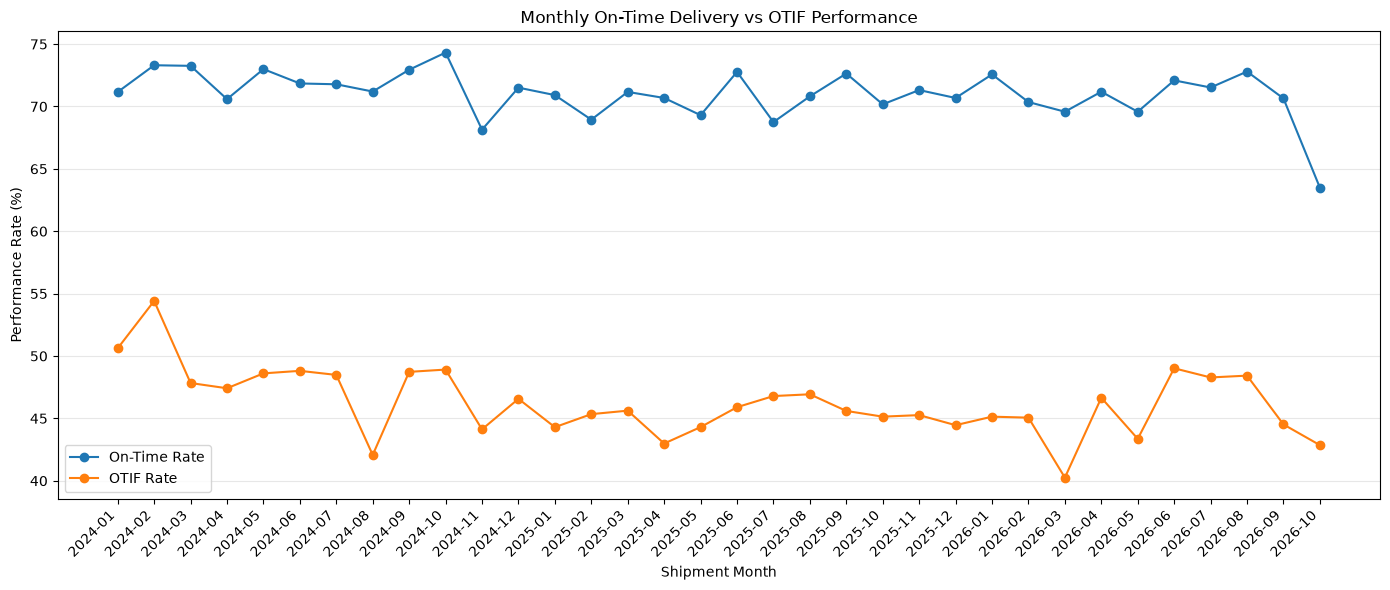

In [20]:
# Monthly On-Time vs OTIF trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_delivery["shipment_year_month"],
    monthly_delivery["on_time_rate_pct"],
    marker="o",
    label="On-Time Rate"
)

plt.plot(
    monthly_delivery["shipment_year_month"],
    monthly_delivery["otif_rate_pct"],
    marker="o",
    label="OTIF Rate"
)

plt.title(
    "Monthly On-Time Delivery vs OTIF Performance"
)

plt.xlabel("Shipment Month")
plt.ylabel("Performance Rate (%)")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 19 — On-Time and OTIF Performance by Order Priority

Visualize delivery performance across order-priority levels.

This chart highlights whether higher-priority orders receive better fulfillment service and makes the performance gap between Normal/Low and High/Urgent orders easier to identify.

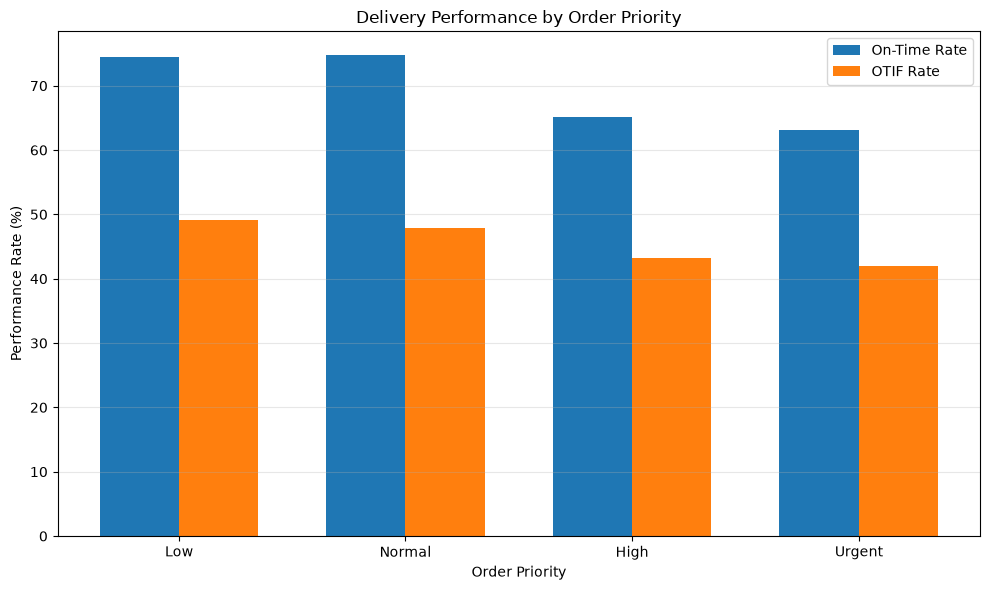

In [21]:
# Set logical priority order

priority_order = [
    "Low",
    "Normal",
    "High",
    "Urgent"
]

priority_chart = (
    priority_delivery
    .set_index("priority")
    .reindex(priority_order)
)


x = np.arange(len(priority_chart))
width = 0.35


plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    priority_chart["on_time_rate_pct"],
    width,
    label="On-Time Rate"
)

plt.bar(
    x + width / 2,
    priority_chart["otif_rate_pct"],
    width,
    label="OTIF Rate"
)

plt.title(
    "Delivery Performance by Order Priority"
)

plt.xlabel("Order Priority")
plt.ylabel("Performance Rate (%)")

plt.xticks(
    x,
    priority_chart.index
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 20 — Delivery Performance by Warehouse

Visualize On-Time and OTIF performance across fulfillment warehouses.

This comparison helps identify whether delivery reliability differs materially across warehouse locations and highlights locations requiring operational attention.

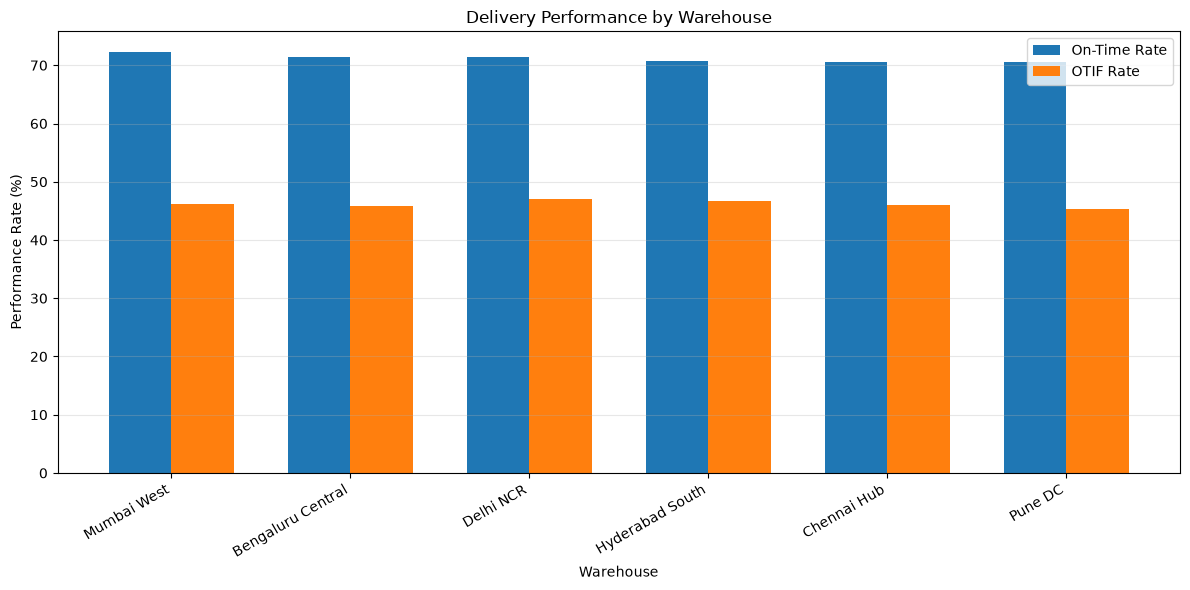

In [22]:
# Sort warehouses by On-Time performance

warehouse_chart = (
    warehouse_delivery
    .sort_values(
        "on_time_rate_pct",
        ascending=False
    )
)


x = np.arange(len(warehouse_chart))
width = 0.35


plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    warehouse_chart["on_time_rate_pct"],
    width,
    label="On-Time Rate"
)

plt.bar(
    x + width / 2,
    warehouse_chart["otif_rate_pct"],
    width,
    label="OTIF Rate"
)

plt.title(
    "Delivery Performance by Warehouse"
)

plt.xlabel("Warehouse")
plt.ylabel("Performance Rate (%)")

plt.xticks(
    x,
    warehouse_chart["warehouse_name"],
    rotation=30,
    ha="right"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 21 — Shipment & Delivery Risk Summary

Consolidate the major shipment and delivery-performance risks identified throughout the analysis.

This summary highlights the weakest-performing priority, region, warehouse, severe-delay concentration, and overall OTIF fulfillment gap.

In [23]:
# Identify key shipment and delivery risk areas

lowest_ontime_priority = (
    priority_delivery
    .sort_values("on_time_rate_pct")
    .iloc[0]
)

lowest_otif_priority = (
    priority_delivery
    .sort_values("otif_rate_pct")
    .iloc[0]
)

lowest_ontime_region = (
    region_delivery
    .sort_values("on_time_rate_pct")
    .iloc[0]
)

lowest_ontime_warehouse = (
    warehouse_delivery
    .sort_values("on_time_rate_pct")
    .iloc[0]
)

lowest_otif_warehouse = (
    warehouse_delivery
    .sort_values("otif_rate_pct")
    .iloc[0]
)

highest_severe_delay_warehouse = (
    warehouse_severe_delays.iloc[0]
)


print("SHIPMENT & DELIVERY RISK SUMMARY\n")

print(
    f"Overall On-Time Rate              : "
    f"{on_time_rate:.2f}%"
)

print(
    f"Overall OTIF Rate                 : "
    f"{otif_rate:.2f}%"
)

print(
    f"Overall Late Shipment Rate        : "
    f"{100 - on_time_rate:.2f}%"
)

print(
    f"Average Delivery Delay            : "
    f"{avg_delivery_delay:.2f} days"
)

print()

print(
    f"Lowest On-Time Priority            : "
    f"{lowest_ontime_priority['priority']} "
    f"({lowest_ontime_priority['on_time_rate_pct']:.2f}%)"
)

print(
    f"Lowest OTIF Priority               : "
    f"{lowest_otif_priority['priority']} "
    f"({lowest_otif_priority['otif_rate_pct']:.2f}%)"
)

print(
    f"Lowest On-Time Customer Region     : "
    f"{lowest_ontime_region['region']} "
    f"({lowest_ontime_region['on_time_rate_pct']:.2f}%)"
)

print(
    f"Lowest On-Time Warehouse           : "
    f"{lowest_ontime_warehouse['warehouse_name']} "
    f"({lowest_ontime_warehouse['on_time_rate_pct']:.2f}%)"
)

print(
    f"Lowest OTIF Warehouse              : "
    f"{lowest_otif_warehouse['warehouse_name']} "
    f"({lowest_otif_warehouse['otif_rate_pct']:.2f}%)"
)

print(
    f"Highest Severe-Delay Warehouse     : "
    f"{highest_severe_delay_warehouse['warehouse_name']} "
    f"({highest_severe_delay_warehouse['severe_delay_shipments']:,.0f} shipments)"
)

print()

print(
    f"6+ Day Late Shipments              : "
    f"{len(severe_delay_shipments):,}"
)

print(
    f"On-Time but Not In-Full Shipments  : "
    f"{on_time_not_in_full:,}"
)

SHIPMENT & DELIVERY RISK SUMMARY

Overall On-Time Rate              : 71.22%
Overall OTIF Rate                 : 46.25%
Overall Late Shipment Rate        : 28.78%
Average Delivery Delay            : 0.93 days

Lowest On-Time Priority            : Urgent (63.08%)
Lowest OTIF Priority               : Urgent (41.96%)
Lowest On-Time Customer Region     : Central (69.73%)
Lowest On-Time Warehouse           : Pune DC (70.54%)
Lowest OTIF Warehouse              : Pune DC (45.39%)
Highest Severe-Delay Warehouse     : Bengaluru Central (659 shipments)

6+ Day Late Shipments              : 2,961
On-Time but Not In-Full Shipments  : 5,076


## Step 22 — Shipment & Delivery Reconciliation

Validate the core shipment and delivery metrics used throughout the analysis.

The reconciliation confirms that:

- Valid and invalid chronology records reconcile to total shipments
- On-Time and Late shipments reconcile to valid shipments
- OTIF and Non-OTIF shipments reconcile to valid shipments
- Delivery-delay bands reconcile to valid shipments
- Late-severity bands reconcile to total late shipments
- Severe-delay warehouse analysis reconciles to 6+ day late shipments
- Warehouse-level shipment counts reconcile to valid shipments

This ensures that the analytical results are internally consistent before final business conclusions are documented.

In [24]:
# Shipment & Delivery reconciliation

chronology_total = (
    valid_shipment_count
    + invalid_shipment_count
)

delivery_status_total = (
    on_time_shipments
    + late_shipments
)

otif_status_total = (
    otif_shipments
    + non_otif_shipments
)

delay_band_total = (
    delivery_delay_summary["shipment_count"].sum()
)

late_severity_total = (
    late_severity_summary["shipment_count"].sum()
)

warehouse_total = (
    warehouse_delivery["shipment_count"].sum()
)

severe_delay_warehouse_total = (
    warehouse_severe_delays[
        "severe_delay_shipments"
    ].sum()
)


print("SHIPMENT & DELIVERY RECONCILIATION\n")

print(
    f"Total Shipment Records              : "
    f"{total_shipments:,}"
)

print(
    f"Valid + Invalid Chronology          : "
    f"{chronology_total:,}"
)

print()

print(
    f"Valid Shipment Records              : "
    f"{valid_shipment_count:,}"
)

print(
    f"On-Time + Late Shipments            : "
    f"{delivery_status_total:,}"
)

print(
    f"OTIF + Non-OTIF Shipments           : "
    f"{otif_status_total:,}"
)

print(
    f"Delay Band Classified Shipments     : "
    f"{delay_band_total:,.0f}"
)

print(
    f"Warehouse Classified Shipments      : "
    f"{warehouse_total:,.0f}"
)

print()

print(
    f"Late Shipment Records               : "
    f"{late_shipments:,}"
)

print(
    f"Late Severity Classified Shipments  : "
    f"{late_severity_total:,.0f}"
)

print()

print(
    f"6+ Day Late Shipments               : "
    f"{len(severe_delay_shipments):,}"
)

print(
    f"Warehouse Severe-Delay Total        : "
    f"{severe_delay_warehouse_total:,.0f}"
)


shipment_reconciliation_passed = (
    chronology_total == total_shipments
    and delivery_status_total == valid_shipment_count
    and otif_status_total == valid_shipment_count
    and delay_band_total == valid_shipment_count
    and warehouse_total == valid_shipment_count
    and late_severity_total == late_shipments
    and severe_delay_warehouse_total
        == len(severe_delay_shipments)
)


print(
    "\nSHIPMENT & DELIVERY RECONCILIATION STATUS :",
    "PASSED"
    if shipment_reconciliation_passed
    else "REVIEW REQUIRED"
)

SHIPMENT & DELIVERY RECONCILIATION

Total Shipment Records              : 24,798
Valid + Invalid Chronology          : 24,798

Valid Shipment Records              : 20,331
On-Time + Late Shipments            : 20,331
OTIF + Non-OTIF Shipments           : 20,331
Delay Band Classified Shipments     : 20,331
Warehouse Classified Shipments      : 20,331

Late Shipment Records               : 5,851
Late Severity Classified Shipments  : 5,851

6+ Day Late Shipments               : 2,961
Warehouse Severe-Delay Total        : 2,961

SHIPMENT & DELIVERY RECONCILIATION STATUS : PASSED


## Step 23 — Key Business Insights

### Overall Delivery Performance

The analysis contains **24,798 shipment records**, of which **20,331 (81.99%)** have valid shipment chronology and are used for clean delivery-performance measurement.

Across valid shipments, the overall **On-Time Delivery rate is 71.22%**, while **28.78% of shipments are late**.

The average delivery delay is **0.93 days**, with a median delay of **0 days**.

### OTIF Performance

Overall **OTIF performance is 46.25%**, significantly below the On-Time Delivery rate of 71.22%.

Of the **14,480 shipments delivered on time**, only **9,404 shipments (64.94%)** also satisfied the In-Full requirement.

A further **5,076 On-Time shipments (35.06%)** failed the In-Full requirement.

This indicates that delivery timeliness alone is not the primary fulfillment challenge. Improving order completeness is also essential for increasing OTIF performance.

### Late Delivery Severity

A total of **5,851 valid shipments were delivered late**.

Late shipments are concentrated in more severe delay categories:

- **1–2 Days Late:** 1,064 shipments (18.18% of late shipments)
- **3–5 Days Late:** 1,826 shipments (31.21%)
- **6+ Days Late:** 2,961 shipments (50.61%)

The 6+ day late group has an average delay of approximately **7.99 days**, while the maximum valid delivery delay is **10 days**.

Therefore, more than half of all late shipments represent significant delivery failures rather than minor operational slippage.

### Order Priority Risk

Order priority shows one of the strongest differences in delivery performance.

**Normal orders achieve a 74.72% On-Time rate**, while **Low-priority orders achieve 74.40%**.

Performance deteriorates significantly for higher-priority orders:

- **High Priority:** 65.18% On-Time
- **Urgent:** 63.08% On-Time

Urgent orders also have the lowest **OTIF rate at 41.96%** and the highest average delay at approximately **1.40 days**.

This suggests that priority escalation is associated with more difficult fulfillment conditions and should be investigated operationally.

### Warehouse Performance

Warehouse-level On-Time performance is relatively concentrated, ranging from approximately **70.54% to 72.22%**.

**Mumbai West** has the highest On-Time Delivery rate at **72.22%**, while **Pune DC** has the lowest at **70.54%**.

For OTIF, **Delhi NCR performs best at 47.12%**, while **Pune DC has the lowest OTIF rate at 45.39%**.

Because the warehouse performance range is relatively narrow, the overall OTIF problem appears to be network-wide rather than caused by a single warehouse.

### Severe Delay Concentration

**Bengaluru Central** contributes the highest number of 6+ day late shipments with **659 shipments**, representing **22.26% of all severe delays**.

It is followed by:

- Delhi NCR — 551
- Mumbai West — 503
- Hyderabad South — 446
- Chennai Hub — 428
- Pune DC — 374

However, average severe-delay duration remains close to **8 days across all warehouses**, indicating that severe delivery failures occur throughout the fulfillment network.

### Customer Region Performance

Delivery performance also varies moderately by customer region.

**East** has the strongest On-Time Delivery rate at **72.42%** and the highest OTIF rate at **47.74%**.

**Central** has the weakest On-Time Delivery rate at **69.73%**, the highest late-shipment rate at **30.27%**, and the highest average delay at approximately **1.08 days**.

Central-region deliveries therefore warrant additional operational investigation.

### Sales Channel Performance

Sales-channel performance is comparatively stable.

On-Time rates range only from **70.89% for Direct** to **71.52% for Marketplace**.

The narrow difference suggests that **sales channel is not a major driver of delivery-performance variation**.

### Delivery Trend

Annual On-Time Delivery performance remains relatively stable:

- **2024:** 71.85%
- **2025:** 70.70%
- **2026:** 71.08%

However, OTIF remains consistently weaker:

- **2024:** 47.76%
- **2025:** 45.20%
- **2026:** 45.66%

This persistent gap reinforces that fulfillment completeness is a structural performance issue rather than a temporary monthly fluctuation.

### Key Business Takeaway

The shipment network faces two distinct service challenges:

1. **Delivery reliability:** 28.78% of valid shipments arrive late, and more than half of those late shipments are delayed by 6 or more days.

2. **Fulfillment completeness:** 5,076 shipments arrive on time but still fail the In-Full requirement, contributing substantially to the low 46.25% OTIF rate.

Operational improvement should therefore focus on both transportation execution and fulfillment completeness.

Priority should be given to investigating High and Urgent orders, reducing severe delays originating across the warehouse network, improving service to the Central customer region, and identifying the operational causes behind On-Time but Not-In-Full shipments.

## Step 24 — Final Shipment & Delivery Analysis Validation

Perform the final validation of the Shipment & Delivery Analysis notebook.

The validation confirms that:

- Total shipment records remain unchanged
- Valid and invalid chronology records reconcile
- Clean delivery KPIs are available only for valid chronology records
- On-Time and Late classifications reconcile
- OTIF and Non-OTIF classifications reconcile
- Delivery-delay bands cover all valid shipments
- Late-severity classifications reconcile
- Warehouse, priority, sales-channel, and customer-region mappings are complete
- Severe-delay analysis reconciles
- Core delivery KPIs remain within valid ranges

This final validation ensures that the notebook is analytically consistent and ready for downstream reporting and dashboard development.

In [25]:
# Final Shipment & Delivery Analysis validation

validation_checks = {

    "Total Shipment Row Count":
        len(shipments) == 24798,

    "Valid Chronology Count":
        valid_shipment_count == 20331,

    "Invalid Chronology Count":
        invalid_shipment_count == 4467,

    "Chronology Records Reconcile":
        (
            valid_shipment_count
            + invalid_shipment_count
        ) == total_shipments,

    "Clean Delay Missing Only for Invalid":
        (
            shipments[
                "delivery_delay_days_clean"
            ].isna().sum()
            == invalid_shipment_count
        ),

    "Clean On-Time Missing Only for Invalid":
        (
            shipments[
                "on_time_flag_clean"
            ].isna().sum()
            == invalid_shipment_count
        ),

    "Clean OTIF Missing Only for Invalid":
        (
            shipments[
                "otif_flag_clean"
            ].isna().sum()
            == invalid_shipment_count
        ),

    "On-Time + Late Reconcile":
        (
            on_time_shipments
            + late_shipments
        ) == valid_shipment_count,

    "OTIF + Non-OTIF Reconcile":
        (
            otif_shipments
            + non_otif_shipments
        ) == valid_shipment_count,

    "Delay Bands Reconcile":
        (
            delivery_delay_summary[
                "shipment_count"
            ].sum()
            == valid_shipment_count
        ),

    "Late Severity Reconciles":
        (
            late_severity_summary[
                "shipment_count"
            ].sum()
            == late_shipments
        ),

    "Severe Delay Reconciles":
        (
            warehouse_severe_delays[
                "severe_delay_shipments"
            ].sum()
            == len(severe_delay_shipments)
        ),

    "Warehouse Mapping Complete":
        (
            shipment_warehouse[
                "warehouse_name"
            ].isna().sum()
            == 0
        ),

    "Priority Mapping Complete":
        (
            shipment_priority[
                "priority"
            ].isna().sum()
            == 0
        ),

    "Sales Channel Mapping Complete":
        (
            shipment_channel[
                "sales_channel"
            ].isna().sum()
            == 0
        ),

    "Customer Region Mapping Complete":
        (
            shipment_region[
                "region"
            ].isna().sum()
            == 0
        ),

    "On-Time Rate Valid":
        0 <= on_time_rate <= 100,

    "OTIF Rate Valid":
        0 <= otif_rate <= 100,

    "Average Delay Valid":
        avg_delivery_delay >= 0
}


print(
    "FINAL SHIPMENT & DELIVERY ANALYSIS VALIDATION\n"
)

for check, result in validation_checks.items():

    print(
        f"{check:<45} : "
        f"{'PASS' if result else 'FAIL'}"
    )


final_shipment_status = all(
    validation_checks.values()
)


print(
    "\nFINAL SHIPMENT & DELIVERY ANALYSIS STATUS :",
    "PASSED"
    if final_shipment_status
    else "REVIEW REQUIRED"
)

FINAL SHIPMENT & DELIVERY ANALYSIS VALIDATION

Total Shipment Row Count                      : PASS
Valid Chronology Count                        : PASS
Invalid Chronology Count                      : PASS
Chronology Records Reconcile                  : PASS
Clean Delay Missing Only for Invalid          : PASS
Clean On-Time Missing Only for Invalid        : PASS
Clean OTIF Missing Only for Invalid           : PASS
On-Time + Late Reconcile                      : PASS
OTIF + Non-OTIF Reconcile                     : PASS
Delay Bands Reconcile                         : PASS
Late Severity Reconciles                      : PASS
Severe Delay Reconciles                       : PASS
Warehouse Mapping Complete                    : PASS
Priority Mapping Complete                     : PASS
Sales Channel Mapping Complete                : PASS
Customer Region Mapping Complete              : PASS
On-Time Rate Valid                            : PASS
OTIF Rate Valid                               : PASS